# Example: A Linear DQN for Adaptive Drug Dosing
In this example, we learn a chemotherapy dosing policy for the patient of the L12b lab with the deep Q-network (DQN) method. The tumor burden and the toxicity stay continuous numbers between 0 and 1. There is no grid and no table.

In the lab, value iteration and Q-learning worked on a grid of 41 levels per variable. Here, a linear Q-network computes the value of each dose from features of the patient state.

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
>
> * __Build a linear Q-network:__ A linear Q-network computes the value of each dose as a weighted sum of bump-shaped features of the tumor burden and the toxicity. We'll build one with 148 weights and evaluate it at any patient state.
> * __Train the network with DQN:__ The DQN algorithm stores the agent's transitions in a replay buffer and fits the network to targets from a delayed copy of itself. We'll follow an implementation of the algorithm and train the network in a few seconds.
> * __Compare the learned policy with grid policies:__ A policy computed on a grid works for the patient without a grid only if the grid is fine enough. We'll compare the learned doses with value iteration on the 41-level grid of the lab and on a 201-level grid.

Let's get started!
___

## Setup, Data, and Prerequisites

First, we load the local [`Include.jl`](Include.jl) setup file and its required packages.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates [`Include.jl`](Include.jl) in the notebook's global scope. The setup file activates the course project, defines local paths, and loads the course package, this example's code in the [src](src) folder, and the packages used here.

Let's set up our code environment:

In [1]:
# Load packages and paths from this notebook's local setup file -
include(joinpath(@__DIR__, "Include.jl"));

# Choose one theme; after changing it, rerun this cell and the plotting cells -
theme(:default)   # light background
# theme(:dark)   # dark background

In addition to standard Julia libraries, we'll use [the `VLDataScienceMachineLearningPackage.jl` package](https://github.com/varnerlab/VLDataScienceMachineLearningPackage.jl). Check out [the documentation](https://varnerlab.github.io/VLDataScienceMachineLearningPackage.jl/dev/) for more information on the functions, types, and data used in this material.

The patient model is in [src/Patient.jl](src/Patient.jl), and the DQN agent is in [src/DQN.jl](src/DQN.jl).
___

## Task 1: Build the Patient without a Grid
In this task, we build the patient model and treat the patient for one cycle.

The patient state is the pair $(B,Z)$, where $B$ is the tumor burden and $Z$ is the accumulated toxicity, both scaled to lie between 0 and 1. Each treatment cycle, we choose a dose $u$ from $\{0, 1/3, 2/3, 1\}$. As in the lab, the next state is given by:

$$
\begin{align*}
B^{\prime} & = B + g\,B\,(1-B) - k\,u\,B, \\
Z^{\prime} & = Z + b\,u - c\,Z,
\end{align*}
$$

where $g$ is the tumor growth rate, $k$ is the fraction of the tumor killed by a full dose, $b$ is the toxicity added by a full dose, and $c$ is the fraction of the toxicity cleared each cycle. Each new value is clipped to lie between 0 and 1.

The rewards are the same as in the lab:
* A cure, $B^{\prime}\leq 0.10$ with the patient alive, earns 60 and ends the treatment.
* A toxic death, $Z^{\prime}\geq 0.90$, costs 60 and ends the treatment.
* Any other cycle costs $B^{\prime}+Z^{\prime}+0.1\,u$, the tumor and the toxicity left after the cycle plus a small charge for the dose.

The one change from the lab is that $B^{\prime}$ and $Z^{\prime}$ are not rounded to a grid level. Let's build the `patient::MyPatientModel` instance with [the `build(...)` function](src/Patient.jl):

In [2]:
patient = build(MyPatientModel, (
    doses = [0.0, 1/3, 2/3, 1.0], # the dose u of actions 1 to 4
    g = 0.15,       # tumor growth rate per cycle
    k = 0.35,       # fraction of the tumor killed per cycle at full dose
    b = 0.50,       # toxicity added per cycle at full dose
    c = 0.35,       # fraction of the toxicity cleared per cycle
    Bcure = 0.10,   # cured when B ≤ Bcure
    Zlethal = 0.90, # toxic death when Z ≥ Zlethal
    wB = 1.0,       # penalty weight of the tumor burden B′ after a cycle
    wZ = 1.0,       # penalty weight of the toxicity Z′ after a cycle
    wu = 0.10,      # penalty weight of the dose u
    rcure = 60.0,   # reward for a cure
    rdead = -60.0,  # reward for a toxic death
));
γ = 0.95; # discount factor

[The `treat(...)` function](src/Patient.jl) plays the role of the world. Given the state $(B,Z)$ and an action $a$, it returns the next state $(B^{\prime},Z^{\prime})$, the reward $r$, and the done flag, which is `true` if the patient is cured or has died.

Let's give the full dose, action 4, to a patient with a large tumor and no toxicity:

In [3]:
let
    (B′, Z′, r, done) = treat(patient, 0.90, 0.0, 4); # full dose at B = 0.90, Z = 0
    println("B′ = ", round(B′, digits = 4), ", Z′ = ", round(Z′, digits = 4),
        ", r = ", round(r, digits = 4), ", done = ", done)
end

B′ = 0.5985, Z′ = 0.5, r = -1.1985, done = false


The full dose cuts the tumor burden from 0.90 to about 0.60, and the toxicity rises from 0 to 0.50. On the 41-level grid of the lab, the next state would be rounded to $(0.600, 0.500)$.
___

## Task 2: Train a Linear DQN
In this task, we build a linear Q-network, train it with DQN, and follow its greedy policy.

The network computes the value of action $a$ in the state $s=(B,Z)$ as a weighted sum of features. This value is given by:

$$
\begin{equation*}
Q(s,a;\mathbf{W}) = \mathbf{w}_{a}^{\top}\phi(s),
\end{equation*}
$$

where $\mathbf{w}_{a}^{\top}$ is row $a$ of the weight matrix $\mathbf{W}$, and $\phi(s)$ is the feature vector of the state.

Our features are radial basis functions. We place $6\times 6=36$ bump centers $\mathbf{c}_{j}$ on an even grid over the square $0\leq B\leq 1$, $0\leq Z\leq 1$. Bump $j$ is given by:

$$
\begin{equation*}
\phi_{j}(s)=\exp\left(-\frac{\lVert s-\mathbf{c}_{j}\rVert^{2}}{2\sigma^{2}}\right),
\end{equation*}
$$

where $\lVert s-\mathbf{c}_{j}\rVert$ is the straight-line (Euclidean) distance from the state to center $j$, and the width is $\sigma=0.15$. A last feature is the constant 1. Each action then has $37$ weights, and the network has $4\cdot 37=148$ weights in all.

The grid of centers only places the bumps. The network can evaluate any state, not only the centers.

Let's build the network with [the `build(...)` function](src/DQN.jl). All its weights start at zero:

In [4]:
network = build(MyLinearQNetworkModel, (nactions = 4, m = 6, σ = 0.15)); # 4 actions, 6 × 6 bumps of width 0.15
φ = features(network, 0.90, 0.0); # the features of the state B = 0.90, Z = 0
println("number of features: ", length(φ), ", number of weights: ", length(network.W))
println("largest bump at (0.90, 0): ", round(maximum(φ[1:end-1]), digits = 4))

number of features: 37

, number of weights: 148
largest bump at (0.90, 0): 0.8007


The two centers nearest $(0.90, 0)$ are $(0.8, 0)$ and $(1.0, 0)$, both at a distance of 0.10. Their bumps equal $\exp(-0.1^{2}/(2\cdot 0.15^{2}))\approx 0.80$, and a bump would equal 1 at its own center.

### Train the network
[The `mydqn(...)` function](src/DQN.jl) carries out the DQN algorithm of the lecture. Each episode starts the patient at a random state, with $B$ drawn evenly from 0 to 1 and $Z$ drawn evenly from 0 to 0.85. A start with $B\leq 0.10$ is already a cure, and it is drawn again.

Random starts spread the agent's experience over many states, not only the states reached from one start.

We use these settings:
* __Episodes and cycles:__ The agent trains for 3,000 episodes of at most 80 cycles each.
* __Exploration:__ The exploration probability $\epsilon$ falls in a straight line from 1, reaches 0.05 after 66.5 percent of the episodes, then stays at 0.05.
* __Replay buffer:__ The buffer keeps the 20,000 most recent transitions, and training waits for a warm-up of 1,000 transitions.
* __Training step:__ After the warm-up, every cycle takes one gradient step with learning rate $\alpha=0.05$ on a random mini-batch of 32 transitions.
* __Target network:__ The Q-network is copied to the target network every 500 cycles, counted over all episodes.

For the linear network, one gradient step updates the row of each action in the mini-batch. The update of row $a$ is given by:

$$
\begin{equation*}
\mathbf{w}_{a}\gets\mathbf{w}_{a}+\frac{\alpha}{N_{\text{batch}}}\sum_{i\,:\,a_{i}=a}\left(y_{i}-\mathbf{w}_{a}^{\top}\phi(s_{i})\right)\phi(s_{i}),
\end{equation*}
$$

where the sum runs over the transitions $i$ of the mini-batch that took action $a$, and $N_{\text{batch}}=32$ is the mini-batch size. Transition $i$ holds the state $s_{i}$, the action $a_{i}$, the reward $r_{i}$, the next state $s_{i}^{\prime}$, and the done flag $d_{i}$. Its target is given by:

$$
\begin{equation*}
y_{i}=r_{i}+\gamma\,(1-d_{i})\max_{a^{\prime}}Q(s_{i}^{\prime},a^{\prime};\mathbf{W}^{-}),
\end{equation*}
$$

where the maximum runs over the four next actions $a^{\prime}$, and $\mathbf{W}^{-}$ holds the weights of the target network. Every prediction error uses the weights from before the step.

Every random draw comes from a generator seeded with `seed`. A rerun with the same seed gives the same network.

Let's train the network:

In [5]:
training_time = @elapsed result = mydqn(network, patient; episodes = 3000, maxcycles = 80,
    γ = γ, α = 0.05, capacity = 20_000, batchsize = 32, warmup = 1000, C = 500,
    ϵ_start = 1.0, ϵ_floor = 0.05, seed = 1234);
trained = result.network; # the trained network
println("cycles of experience: ", result.cycles, ", gradient steps: ", result.updates)
println("training time: ", round(training_time, digits = 1), " seconds")

cycles of experience: 43609

, gradient steps: 42610
training time: 1.3 seconds


### Follow the learned policy
The learned policy gives each state the dose with the largest Q-value, with no exploration. [The `simulate(...)` function](src/DQN.jl) follows it from a starting state until the patient is cured, dies of toxicity, or 100 cycles have passed. It returns the states, the doses, the outcome, the number of cycles, and the discounted return $G=r_{1}+\gamma r_{2}+\gamma^{2}r_{3}+\dots$

__Prediction:__ Starting from $B=0.90$ and $Z=0$, the patient of the lab, what will the learned policy do: {cure the patient; let the patient die of toxicity; or neither, within 100 cycles}?

In [6]:
run_dqn = simulate(patient, trained; B₀ = 0.90, Z₀ = 0.0, maxcycles = 100, γ = γ);
println("linear DQN: ", run_dqn.outcome, " after ", run_dqn.cycles, " cycles, G = ", round(run_dqn.G, digits = 2))
println("doses: ", round.(run_dqn.dose, digits = 2))

linear DQN: cured after 23 cycles, G = 5.12
doses: 

[0.67, 1.0, 0.67, 0.33, 0.67, 0.67, 0.33, 0.67, 0.33, 0.0, 0.67, 0.0, 1.0, 0.67, 0.33, 0.67, 0.67, 0.33, 0.67, 0.67, 0.33, 0.67, 0.67]


__What do we see?__ The learned policy cures the patient in 23 cycles. It gives the full dose only twice and never two cycles in a row.

The moderate doses in between keep the toxicity below the lethal level while the tumor shrinks.
___

## Task 3: Compare with Grid Policies
In this task, we compare the learned policy with two policies from value iteration, applied to the patient without a grid.

[The `solvegrid(...)` function](src/Patient.jl) runs value iteration on a grid, as in the lab, and returns the optimal action at each grid point. With 41 levels, it gives the optimal policy of the lab. With 201 levels, the grid is five times finer.

To dose the patient without a grid, a grid policy looks up the nearest grid point and gives its action. Let's compute both grid policies and follow them from the same start:

In [7]:
grid_41 = solvegrid(patient; nlevels = 41, γ = γ);   # the lab's grid: 41^2 = 1681 states
grid_201 = solvegrid(patient; nlevels = 201, γ = γ); # a finer grid: 201^2 = 40401 states

run_41 = simulate(patient, grid_41; B₀ = 0.90, Z₀ = 0.0, maxcycles = 100, γ = γ);
run_201 = simulate(patient, grid_201; B₀ = 0.90, Z₀ = 0.0, maxcycles = 100, γ = γ);
println("41-level grid: ", run_41.outcome, " after ", run_41.cycles, " cycles, G = ", round(run_41.G, digits = 2))
println("201-level grid: ", run_201.outcome, " after ", run_201.cycles, " cycles, G = ", round(run_201.G, digits = 2))
println("linear DQN: ", run_dqn.outcome, " after ", run_dqn.cycles, " cycles, G = ", round(run_dqn.G, digits = 2))

41-level grid: timeout

 after 100 cycles, G = -18.21
201-level grid: cured after 19 cycles, G = 10.96
linear DQN: cured after 23 cycles, G = 5.12


Let's plot the tumor burden and the toxicity over the cycles of each policy. The dotted lines mark the cure level and the lethal level. For the 41-level policy, we show the first 40 of its 100 cycles:

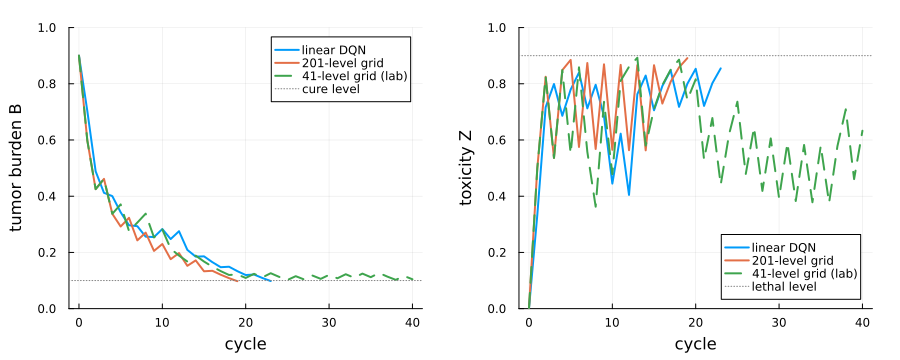

In [8]:
let
    # the tumor burden of each policy, cycle by cycle -
    p1 = plot(0:run_dqn.cycles, run_dqn.B, lw = 2, label = "linear DQN",
        xlabel = "cycle", ylabel = "tumor burden B", ylims = (0, 1))
    plot!(p1, 0:run_201.cycles, run_201.B, lw = 2, label = "201-level grid")
    plot!(p1, 0:40, run_41.B[1:41], lw = 2, ls = :dash, label = "41-level grid (lab)")
    hline!(p1, [patient.Bcure], color = :gray, ls = :dot, label = "cure level")

    # the toxicity of each policy, cycle by cycle -
    p2 = plot(0:run_dqn.cycles, run_dqn.Z, lw = 2, label = "linear DQN",
        xlabel = "cycle", ylabel = "toxicity Z", ylims = (0, 1))
    plot!(p2, 0:run_201.cycles, run_201.Z, lw = 2, label = "201-level grid")
    plot!(p2, 0:40, run_41.Z[1:41], lw = 2, ls = :dash, label = "41-level grid (lab)")
    hline!(p2, [patient.Zlethal], color = :gray, ls = :dot, label = "lethal level")

    plot(p1, p2, layout = (1, 2), size = (900, 360), margin = 5Plots.mm)
end

__What do we see?__ The 201-level policy cures the patient in 19 cycles, and the linear DQN takes 23. The 41-level policy of the lab never cures the patient.

The 41-level policy brings the tumor burden down near the cure level. The tumor then stays between 0.10 and 0.13.

The 41-level grid is too coarse for this patient. A tumor burden of 0.109 rounds to the grid level 0.100, which counts as a cure, and a cured patient gets no dose. The tumor then grows back between doses.

Let's check the dose that each policy gives at the state $(0.109, 0.816)$, which the 41-level policy reaches at the start of cycle 21, after 20 treatments:

In [9]:
let
    B = 0.109; # the tumor burden of a state the 41-level policy reaches
    Z = 0.816; # the toxicity of that state
    println("41-level grid gives the dose ", patient.doses[gridaction(grid_41, B, Z)])
    println("201-level grid gives the dose ", round(patient.doses[gridaction(grid_201, B, Z)], digits = 2))
    println("linear DQN gives the dose ", round(patient.doses[greedyaction(trained, B, Z)], digits = 2))
end

41-level grid gives the dose 0.0
201-level grid gives the dose 0.67
linear DQN gives the dose 0.67


### Other starting states
One start can be lucky. Let's follow the learned policy and the 201-level policy from eight starting states, with tumor burdens from 0.3 to 0.9 and toxicities of 0 and 0.4:

In [10]:
comparison = DataFrame(B₀ = Float64[], Z₀ = Float64[], dqn_outcome = Symbol[], dqn_cycles = Int64[],
    grid_outcome = Symbol[], grid_cycles = Int64[]);
for B₀ ∈ [0.3, 0.5, 0.7, 0.9]
    for Z₀ ∈ [0.0, 0.4]
        a = simulate(patient, trained; B₀ = B₀, Z₀ = Z₀, γ = γ); # the linear DQN policy
        g = simulate(patient, grid_201; B₀ = B₀, Z₀ = Z₀, γ = γ); # the 201-level grid policy
        push!(comparison, (B₀, Z₀, a.outcome, a.cycles, g.outcome, g.cycles));
    end
end
pretty_table(comparison; backend = :text, fit_table_in_display_horizontally = false)

┌─────────┬─────────┬─────────────┬────────────┬──────────────┬─────────────┐
│      B₀ │      Z₀ │ dqn_outcome │ dqn_cycles │ grid_outcome │ grid_cycles │
│ Float64 │ Float64 │      Symbol │      Int64 │       Symbol │       Int64 │
├─────────┼─────────┼─────────────┼────────────┼──────────────┼─────────────┤
│     0.3 │     0.0 │       cured │         12 │        cured │          10 │
│     0.3 │     0.4 │       cured │         13 │        cured │          13 │
│     0.5 │     0.0 │       cured │         20 │        cured │          16 │
│     0.5 │     0.4 │       cured │         21 │        cured │          17 │
│     0.7 │     0.0 │       cured │         20 │        cured │          19 │
│     0.7 │     0.4 │       cured │         22 │        cured │          19 │
│     0.9 │     0.0 │       cured │         23 │        cured │          19 │
│     0.9 │     0.4 │       cured │         24 │        cured │          20 │
└─────────┴─────────┴─────────────┴────────────┴──────────────┴─

__What do we see?__ The learned policy cures the patient from all eight starts. It needs as many cycles as the 201-level policy, or up to four more.

A Q-table on the 201-level grid would need $40401\cdot 4=161604$ entries, about a thousand times the 148 weights of our network. The number of entries also grows exponentially with every state variable we add.

### Check: The Linear DQN
We check the network, the training, and the comparison:
* __The network:__ It has 37 features, and each bump equals 1 at its own center. Its Q-values are the weights times the features.
* __The training:__ It leaves the untrained network unchanged, and a rerun with the same seed gives the same weights.
* __The comparison:__ The learned policy cures the patient from every start in the table. The 41-level policy of the lab never cures the patient without a grid.

Let's run the checks:

In [11]:
@testset "Linear DQN dosing" begin

    # the network: 37 features, a bump equals 1 at its center, and Q = W⋅φ -
    @test length(features(network, 0.5, 0.5)) == 37
    @test features(network, 1.0, 0.0)[31] ≈ 1.0 # center 31 is (1.0, 0.0)
    @test qvalues(trained, 0.5, 0.2) ≈ trained.W*features(trained, 0.5, 0.2)

    # the training: the untrained network is unchanged, and a rerun gives the same weights -
    @test all(network.W .== 0.0)
    rerun = mydqn(network, patient; episodes = 3000, maxcycles = 80, γ = γ, α = 0.05,
        capacity = 20_000, batchsize = 32, warmup = 1000, C = 500, seed = 1234);
    @test rerun.network.W == trained.W

    # the comparison: the learned policy cures from every start, and the 41-level policy never does -
    @test all(comparison.dqn_outcome .== :cured)
    @test all(comparison.dqn_cycles .>= comparison.grid_cycles)
    @test run_41.outcome == :timeout
    @test patient.doses[gridaction(grid_41, 0.109, 0.816)] == 0.0
end;

Test Summary:     | Pass  

Total  Time
Linear DQN dosing |    9      9  1.0s


___

## Summary
In this example, we learned a dosing policy for the patient of the lab with a linear DQN, without rounding the patient state to a grid.

> __Key Takeaways:__
>
> * __A linear Q-network replaces the table:__ Our network computed the value of each dose from 37 features of the tumor burden and the toxicity, with 148 weights in all. It gave a dose for every patient state, with no grid and no rounding.
>
> * __The trained network cures the patient:__ After 3,000 training episodes, the greedy policy cured the patient from every start we tried. It needed as many cycles as value iteration on a 201-level grid, or up to four more.
>
> * __A coarse grid can break a policy:__ The 41-level policy of the lab never cured the patient without a grid, because rounding made a tumor burden of 0.109 look like a cure. The 201-level grid policy cured the patient, but a Q-table on that grid would hold about a thousand times as many numbers as our network.

A Q-network with a few well-chosen features handles a continuous state with a small, fixed number of weights.

___